# HDB resale prices: data and evaluation

Estimate individual transaction prices from recorded property attributes and month. This notebook describes the frozen snapshot; it is not a current valuation service.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SMOKE = os.environ.get("HDB_SMOKE") == "1"
DATA = ROOT / ("tests/fixtures/transactions.csv" if SMOKE else "data/raw/resale.csv")
RUNS = Path(os.environ.get("HDB_RUN_ROOT", str(ROOT / "artifacts")))

import matplotlib.pyplot as plt
from IPython.display import display

print(f"Data: {DATA.name}; mode: {'synthetic smoke' if SMOKE else 'frozen snapshot'}")

Data: resale.csv; mode: frozen snapshot


In [2]:
from hdb_resale.data import load_data, split_data
from hdb_resale.plots import plot_monthly_prices

data = load_data(DATA)
splits = split_data(data)
{name: len(frame) for name, frame in splits.items()}

{'train': 169150, 'validation': 27835, 'test': 5414}

## Evaluation comes before modelling

Train through 2023; use 2024 for validation; reserve January–March 2025 for final historical evaluation. Preprocessing learns only from training rows. March may be incomplete. The original project already inspected 2025, so this is not an untouched prospective test.

## Data quality and coverage

Check missingness, category coverage, repeated rows, and split sizes before modelling. Repeated rows remain because the source has no unique transaction identifier.

In [3]:
import pandas as pd

display(pd.DataFrame({"missing": data.isna().sum(), "unique": data.nunique()}))
print(f"Repeated full rows: {data.duplicated().sum():,}")
display(
    pd.DataFrame(
        {name: frame["resale_price"].describe() for name, frame in splits.items()}
    ).T
)

,missing,unique
month,0,99
town,0,26
flat_type,0,7
block,0,2733
street_name,0,571
storey_range,0,17
floor_area_sqm,0,179
flat_model,0,21
lease_commence_date,0,56
remaining_lease,0,685


Repeated full rows: 298


,count,mean,std,min,25%,50%,75%,max
train,169150.0,490971.586249,169845.076234,140000.0,365000.0,460000.0,583000.0,1500000.0
validation,27835.0,612591.918423,188590.996391,230000.0,480000.0,590000.0,715000.0,1588000.0
test,5414.0,640161.441906,197472.303071,250000.0,500000.0,618000.0,750000.0,1600000.0


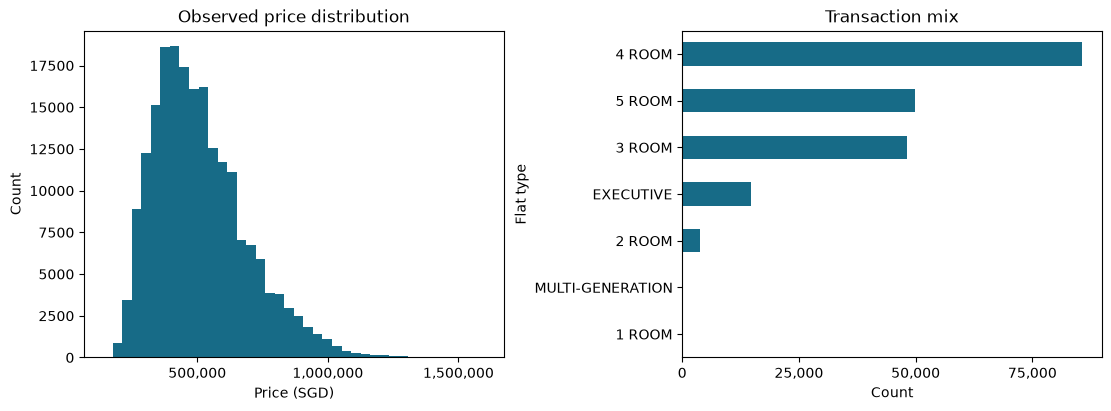

In [4]:
from hdb_resale.plots import plot_data_profile

figure = plot_data_profile(data)
if not SMOKE:
    (ROOT / "reports/figures").mkdir(parents=True, exist_ok=True)
    figure.savefig(ROOT / "reports/figures/data_profile.png", dpi=160)
display(figure)
plt.close(figure)

Price spread and the mix of flat types affect aggregate dollar errors. Compare split summaries before interpreting validation-to-test degradation. These descriptive checks do not fit preprocessing or tune models on test labels.

In [5]:
data[list(data.columns)].describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
month,202399,NaN,NaN,NaN,2021-04-22 07:26:52.306385,2017-01-01 00:00:00,2019-06-01 00:00:00,2021-06-01 00:00:00,2023-04-01 00:00:00,2025-03-01 00:00:00,NaN
town,202399,26,SENGKANG,16679,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flat_type,202399,7,4 ROOM,85564,NaN,NaN,NaN,NaN,NaN,NaN,NaN
block,202399,2733,2,614,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street_name,202399,571,YISHUN RING RD,2909,NaN,NaN,NaN,NaN,NaN,NaN,NaN
storey_range,202399,17,04 TO 06,46517,NaN,NaN,NaN,NaN,NaN,NaN,NaN
floor_area_sqm,202399.0,NaN,NaN,NaN,96.937723,31.0,82.0,93.0,112.0,366.7,24.029455
flat_model,202399,21,Model A,71454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lease_commence_date,202399.0,NaN,NaN,NaN,1996.242012,1966.0,1985.0,1996.0,2011.0,2021.0,14.185842
remaining_lease,202399,685,94 years 10 months,1818,NaN,NaN,NaN,NaN,NaN,NaN,NaN


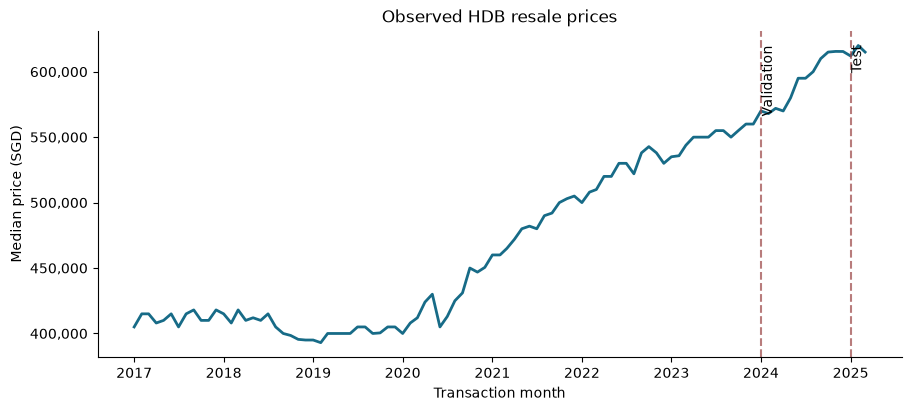

In [6]:
figure = plot_monthly_prices(data)
if not SMOKE:
    figure.savefig(ROOT / "reports/figures/monthly_prices.png", dpi=160)
display(figure)
plt.close(figure)

## Data decisions

The snapshot has no transaction identifier. Repeated attribute rows are retained, since different sales can share the same recorded attributes. Lease duration and storey bounds become numeric features. Block identifiers are excluded; street, town, flat type, and flat model remain categorical.

Observed monthly medians describe the mix of transactions, not a constant-quality house price index. No causal claims are made.

**Next:** the baseline notebook establishes whether property attributes improve on a constant median prediction.